## Problem Statement:

### Given data about COVID-19 patients, write code to visualize the impact and analyze the trend of rate of infection and recovery as well as make predictions about the number of cases expected a week in future based on the current trends.

##Dataset:

### CSV and Excel files containing data about the number of COVID-19 confirmed deaths and recovered patients both around the world and in India. Download Link

## Guidelines:

### ● Usepandas to accumulate data from multiple data files.
### ● Useplotly (visualization library) to create interactive visualizations.
### ● UseFacebook prophet library to make time series models.
### ● Visualize the prediction by combining these technologies.

## Import libraries

In [298]:
!pip install pandas numpy plotly prophet openpyxl

In [299]:
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt


from prophet import Prophet


import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from math import sqrt

## Load the COVID-19 dataset

In [300]:
covid19_df = pd.read_csv('/content/Covid_19_Clean_Complete.csv')

### Understand the dataset

In [301]:
#Check top 5 records
covid19_df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [302]:
# Shapr of dataset rows and columns
covid19_df.shape

(49068, 10)

In [303]:
covid19_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


### Date column is shows as object data type. We will convert this to DateTime format.

In [304]:
#Display all column names
covid19_df.columns

Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='object')

In [305]:
#Check Null values
covid19_df.isnull().sum()

,0
Province/State,34404
Country/Region,0
Lat,0
Long,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
WHO Region,0


### As we observe from above data Province/State contains missing values. This is expected because some countries do not have province-level records.

In [306]:
# Convert Date column type from Object to DateTime
covid19_df['Date'] = pd.to_datetime(covid19_df['Date'])

In [307]:
# Verify if Dtype of Date column is changed
covid19_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Province/State  14664 non-null  object        
 1   Country/Region  49068 non-null  object        
 2   Lat             49068 non-null  float64       
 3   Long            49068 non-null  float64       
 4   Date            49068 non-null  datetime64[ns]
 5   Confirmed       49068 non-null  int64         
 6   Deaths          49068 non-null  int64         
 7   Recovered       49068 non-null  int64         
 8   Active          49068 non-null  int64         
 9   WHO Region      49068 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(4), object(3)
memory usage: 3.7+ MB


In [308]:
#Check duplicate records
covid19_df.duplicated().sum()

np.int64(0)

In [309]:
# Replace null values with keyword lets say "Unknown"
covid19_df['Province/State'] = covid19_df['Province/State'].fillna('Unknown')

In [310]:
covid19_df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,Unknown,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,Unknown,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,Unknown,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,Unknown,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,Unknown,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [311]:
# Check statistical summary
covid19_df.describe()

,Lat,Long,Date,Confirmed,Deaths,Recovered,Active
count,49068.000000,49068.000000,49068,4.906800e+04,49068.000000,4.906800e+04,4.906800e+04
mean,21.433730,23.528236,2020-04-24 12:00:00,1.688490e+04,884.179160,7.915713e+03,8.085012e+03
min,-51.796300,-135.000000,2020-01-22 00:00:00,0.000000e+00,0.000000,0.000000e+00,-1.400000e+01
25%,7.873054,-15.310100,2020-03-08 18:00:00,4.000000e+00,0.000000,0.000000e+00,0.000000e+00
50%,23.634500,21.745300,2020-04-24 12:00:00,1.680000e+02,2.000000,2.900000e+01,2.600000e+01
75%,41.204380,80.771797,2020-06-10 06:00:00,1.518250e+03,30.000000,6.660000e+02,6.060000e+02
max,71.706900,178.065000,2020-07-27 00:00:00,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06
std,24.950320,70.442740,NaN,1.273002e+05,6313.584411,5.480092e+04,7.625890e+04


In [312]:
# Visualize Top 5 countries by Confirmed cases

In [313]:
country_df = covid19_df.groupby(['Country/Region', 'Date'])[['Deaths', 'Active', 'Recovered', 'Confirmed']].sum().reset_index()

latest_date = country_df['Date'].max()

latest_country_df = country_df[country_df['Date'] == latest_date]

top5 = latest_country_df.sort_values(by='Confirmed',ascending=False).head(5)

fig = px.bar(top5, x='Country/Region',y=['Deaths', 'Active', 'Recovered', 'Confirmed'],barmode='group',title='COVID-19 Statistics – Top 5 Countries')

fig.show()

In [314]:
# Check if on same date, country has multiple records on same date. Group by Date
global_df = covid19_df.groupby('Date')[
    ['Confirmed', 'Deaths', 'Recovered', 'Active']
].sum().reset_index()

In [315]:
global_df.head()

,Date,Confirmed,Deaths,Recovered,Active
0,2020-01-22,555,17,28,510
1,2020-01-23,654,18,30,606
2,2020-01-24,941,26,36,879
3,2020-01-25,1434,42,39,1353
4,2020-01-26,2118,56,52,2010


# COVID-19 data in India

In [316]:
india_df = covid19_df[covid19_df['Country/Region'] == 'India'].copy()
india_df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
129,Unknown,India,20.593684,78.96288,2020-01-22,0,0,0,0,South-East Asia
390,Unknown,India,20.593684,78.96288,2020-01-23,0,0,0,0,South-East Asia
651,Unknown,India,20.593684,78.96288,2020-01-24,0,0,0,0,South-East Asia
912,Unknown,India,20.593684,78.96288,2020-01-25,0,0,0,0,South-East Asia
1173,Unknown,India,20.593684,78.96288,2020-01-26,0,0,0,0,South-East Asia


## Daily Infection Rate =  (New cases/Yesterday Confirmed Cases) * 100

## Recovery Rate = (Recovered / Confirmed) * 100

In [317]:
# New cases on daily basis
global_df['New_Cases'] = global_df['Confirmed'].diff()

In [318]:
# Recovered cases on daily basis
global_df['New_Recovered'] = global_df['Recovered'].diff()

In [319]:
# New deaths on daily basis
global_df['New_Deaths'] = global_df['Deaths'].diff()

In [320]:
# Recovery Rate
global_df['Recovery_Rate'] = (global_df['Recovered'] / global_df['Confirmed'].replace(0, np.nan)) * 100

In [321]:
# Visualize Recovery Rate
fig = px.line(global_df,x='Date', y='Recovery_Rate', title='COVID-19 Recovery Rate Trend')

fig.update_layout(yaxis_title='Recovery Rate (%)')

fig.show()

In [322]:
# Death Rate
global_df['Death_Rate'] = (
    global_df['Deaths'] /
    global_df['Confirmed'].replace(0, np.nan)
) * 100

In [323]:
# confirmed cases date wise
fig = px.line(global_df,x='Date', y='Confirmed',title='Trend - COVID-19 Confirmed Cases',labels={'Confirmed': 'Total Confirmed Cases','Date': 'Date'})

fig.show()

In [324]:
# Daily new infection cases
fig = px.bar(global_df,x='Date', y='New_Cases',title='Daily New COVID-19 Cases')

fig.show()

In [325]:
# Infection rate
global_df['Infection_Growth_Rate'] = (
    global_df['New_Cases'] /
    global_df['Confirmed'].shift(1).replace(0, np.nan)
) * 100

fig = px.line(
    global_df,
    x='Date',
    y='Infection_Growth_Rate',
    title='COVID-19 Daily Infection Growth Rate'
)

fig.update_layout(
    yaxis_title='Growth Rate (%)'
)

fig.show()

In [326]:
# India daily new cases
india_df['New_Cases'] = india_df['Confirmed'].diff()

india_df['New_Recovered'] = india_df['Recovered'].diff()

india_df['New_Deaths'] = india_df['Deaths'].diff()

In [327]:
# Recovery Rate in India
india_df['Recovery_Rate'] = (india_df['Recovered'] / india_df['Confirmed'].replace(0, np.nan)) * 100

In [328]:
# Death Rate in India
india_df['Death_Rate'] = (india_df['Deaths'] / india_df['Confirmed'].replace(0, np.nan)) * 100

In [329]:
# Confirmed Cases in India
fig = px.line(india_df,x='Date',y='Confirmed',title='COVID-19 Confirmed Cases in India')

fig.show()

In [330]:
# Recovery Rate in India
fig = px.line(india_df, x='Date',  y='Recovery_Rate', title='COVID-19 Recovery Rate in India')

fig.show()

In [331]:
#Daily New COVID-19 Cases in India
fig = px.bar(india_df,x='Date',y='New_Cases',title='Daily New COVID-19 Cases in India')

fig.show()

# Seasonal Decomposition Before Prophet model

In [332]:
def seasonal_decomposition(df,columnName):

  # Select Date and required column
  prophet_df = df[['Date', columnName]].copy()

  # Rename columns as required by Prophet
  prophet_df.rename(columns={'Date': 'ds',columnName: 'y'},inplace=True)

  # Sort data by date
  prophet_df = prophet_df.sort_values('ds')

  prophet_df['ds'] = pd.to_datetime(prophet_df['ds'])

  prophet_df = prophet_df.sort_values('ds')

  prophet_df.set_index('ds', inplace=True)

  decomposition = seasonal_decompose(prophet_df['y'],model='additive',period=7)

  fig = decomposition.plot()

  fig.set_size_inches(14, 10)

  plt.show()



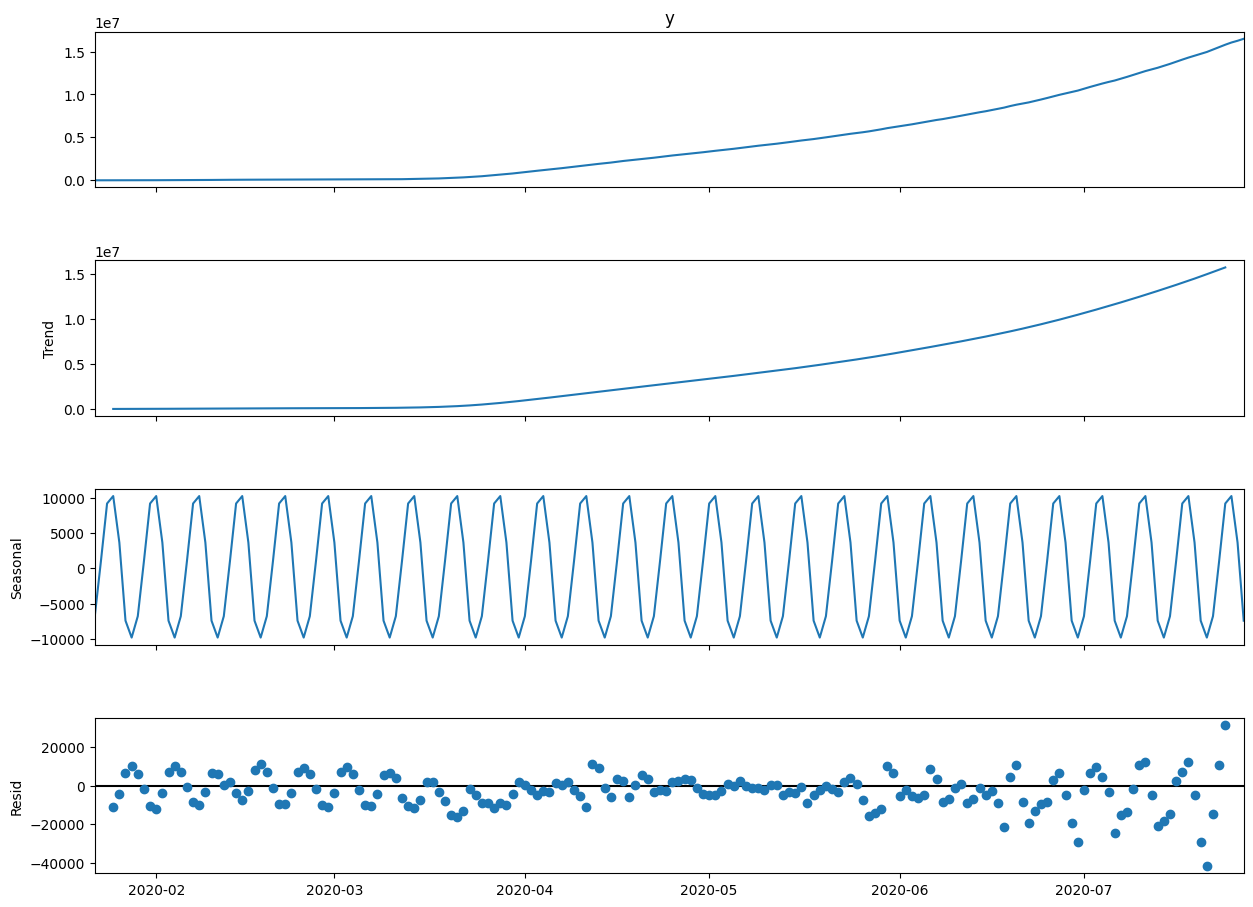

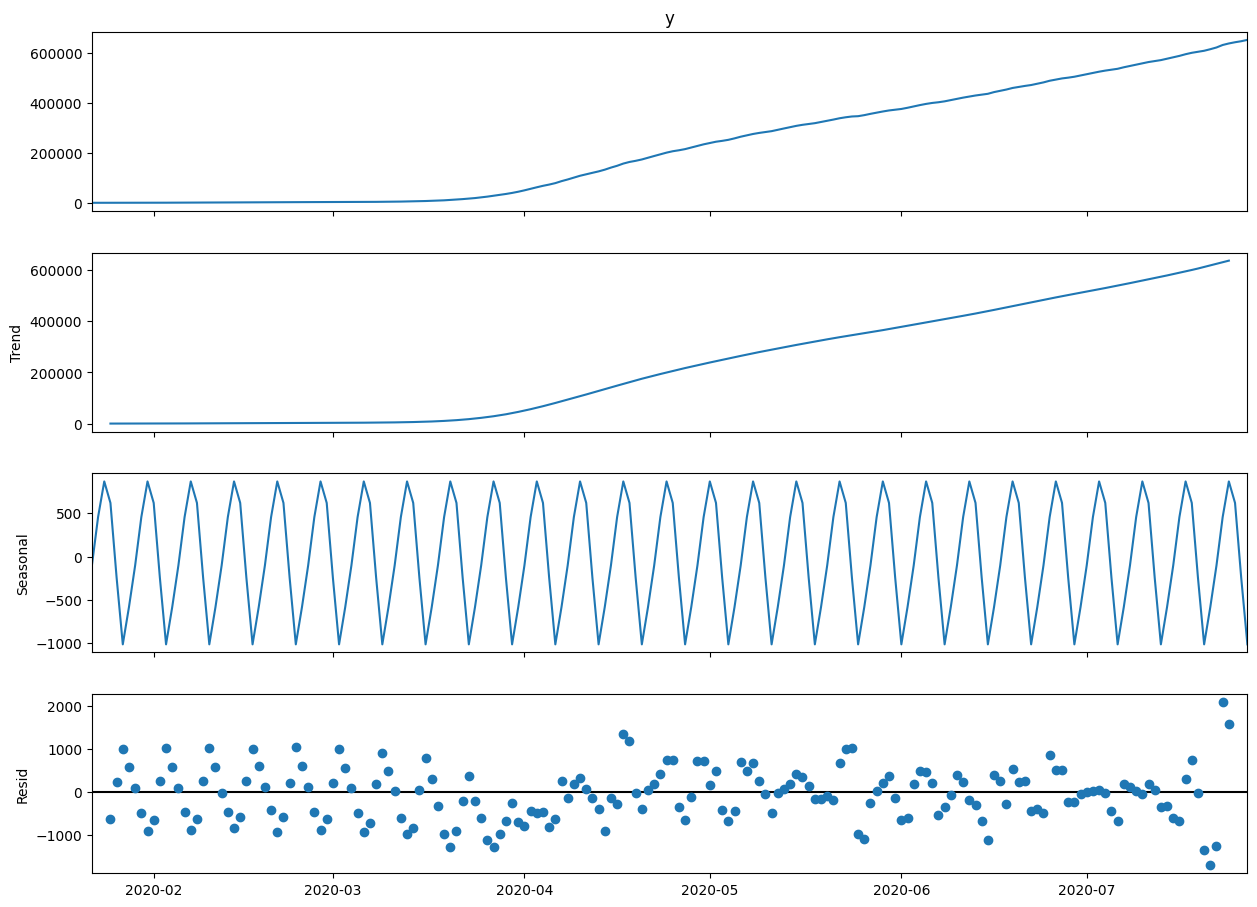

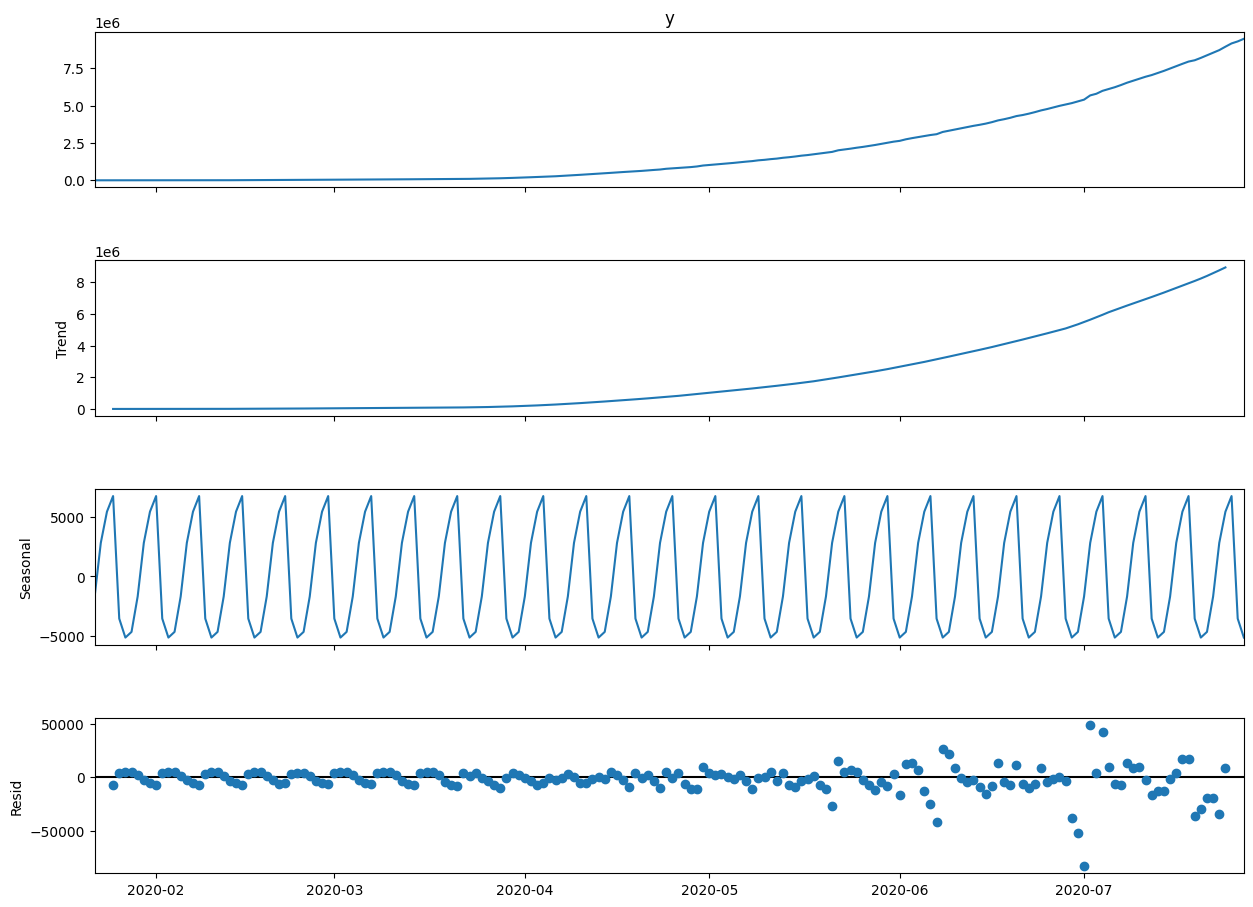

In [333]:
seasonal_decomposition(global_df,"Confirmed")
seasonal_decomposition(global_df,"Deaths")
seasonal_decomposition(global_df,"Recovered")

## Time-series forecasting using Facebook Prophet

### As per current understanding Prophet requires the input DataFrame to contain exactly two mandatory columns (ds and y)

### ds: This means Date

### y:  This means value to predict

### Prophet is a time-series forecasting library developed by Facebook (now Meta).

### It identifies patterns in historical data and uses them to forecast future values.

### Its main components include:

### 1. Trend – Overall direction of the data (increasing or decreasing).

### 2. Seasonality – Repeating patterns over time (daily, weekly, yearly).

### 3. Holidays – Effects of special holidays and events, when configured.

In [334]:
# Function to forecast using Prophet model. Input parameters are dataFrame, Dataset Column under analysis and days as 7.
def prophet_forecast(df, column, days=7):

  # Select Date and required column
  prophet_df = df[['Date', column]].copy()

  # Rename columns as required by Prophet
  prophet_df.rename(columns={'Date': 'ds', column: 'y'},inplace=True)

  # Sort data by date
  prophet_df = prophet_df.sort_values('ds')

  # Create the Prophet model
  model = Prophet(
    weekly_seasonality=False,
    daily_seasonality=False,
    yearly_seasonality=False
  )

  # Train the model
  model.fit(prophet_df)

  # Generate future dates
  future = model.make_future_dataframe(periods=days,freq='D')

  # Generate predictions
  forecast = model.predict(future)


  # Extract future predictions only
  forecast_result = forecast[
        forecast['ds'] > prophet_df['ds'].max()
    ][['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

  return model, forecast, forecast_result


In [335]:
confirmed_model, confirmed_forecast, confirmed_7days = prophet_forecast(global_df,'Confirmed')

In [336]:
deaths_model, deaths_forecast, deaths_7days = prophet_forecast(global_df,'Deaths')

In [337]:
recovered_model, recovered_forecast, recovered_7days = prophet_forecast(global_df,'Recovered')

In [338]:
def plot_forecast(df, column, forecast_result):

    fig = go.Figure()

    # Actual historical data
    fig.add_trace(
        go.Scatter(
            x=df['Date'],
            y=df[column],
            mode='lines',
            name='Actual ' + column
        )
    )

    # Predicted data
    fig.add_trace(
        go.Scatter(
            x=forecast_result['ds'],
            y=forecast_result['yhat'],
            mode='lines+markers',
            name='Predicted ' + column
        )
    )

    fig.update_layout(
        title=f'{column} – Actual vs 7-Day Forecast',
        xaxis_title='Date',
        yaxis_title='Number of Cases',
        hovermode='x unified'
    )

    fig.show()

In [339]:
plot_forecast(global_df, 'Confirmed', confirmed_7days)

In [340]:
plot_forecast(global_df, 'Deaths', deaths_7days)

In [341]:
plot_forecast(global_df, 'Recovered', recovered_7days)

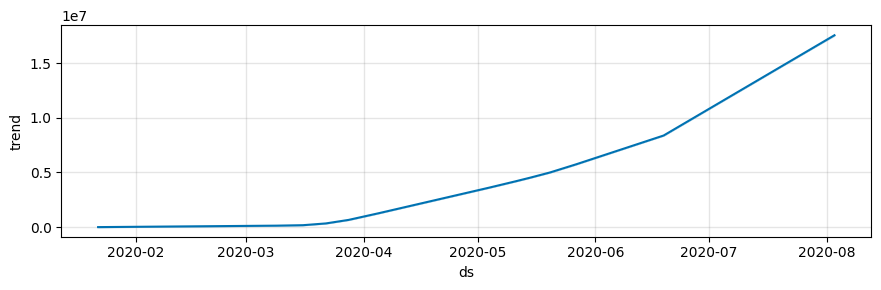

In [342]:
confirmed_model.plot_components(confirmed_forecast)
plt.show()

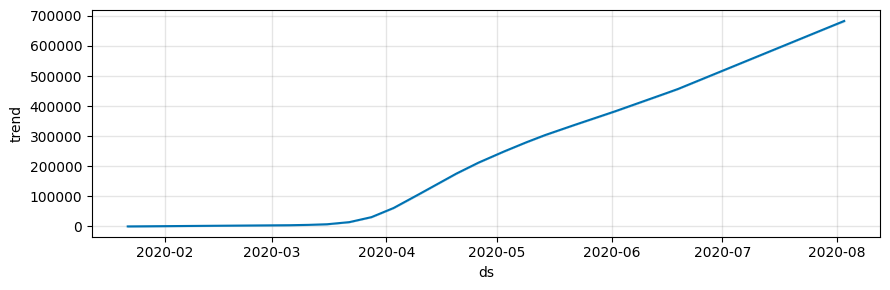

In [343]:
deaths_model.plot_components(deaths_forecast)
plt.show()

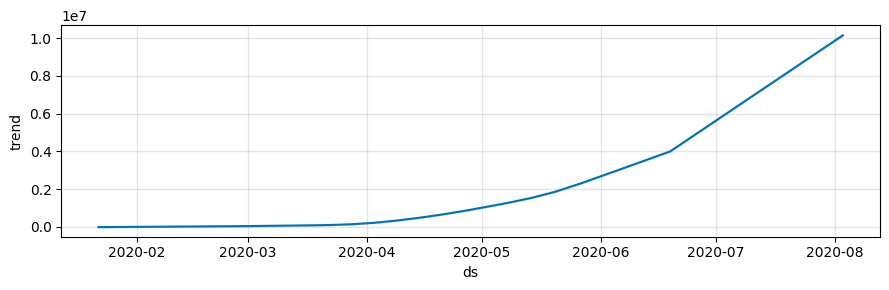

In [344]:
recovered_model.plot_components(recovered_forecast)
plt.show()

In [345]:
print("Confirmed Cases Forecast")

display(confirmed_7days)

print("\n**********************************************************\n")
print("Deaths Forecast")

display(deaths_7days)

print("\n**********************************************************\n")
print("Recovered Cases Forecast")

display(recovered_7days)

Confirmed Cases Forecast


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,1.633805e+07,1.623817e+07,1.644603e+07
189,2020-07-29,1.654212e+07,1.643616e+07,1.665111e+07
190,2020-07-30,1.674618e+07,1.663472e+07,1.685926e+07
191,2020-07-31,1.695025e+07,1.683681e+07,1.706600e+07
192,2020-08-01,1.715431e+07,1.704616e+07,1.726873e+07
193,2020-08-02,1.735838e+07,1.724472e+07,1.746894e+07
194,2020-08-03,1.756244e+07,1.743060e+07,1.767946e+07



**********************************************************

Deaths Forecast


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,653032.112821,650961.499553,655283.344306
189,2020-07-29,658061.034609,655665.671444,660247.496757
190,2020-07-30,663089.956396,660872.469528,665441.345580
191,2020-07-31,668118.878183,665945.695015,670452.967436
192,2020-08-01,673147.799970,670781.371675,675850.756765
193,2020-08-02,678176.721757,675523.781688,681022.711302
194,2020-08-03,683205.643544,680216.187124,686359.014594



**********************************************************

Recovered Cases Forecast


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,9.322474e+06,9.247545e+06,9.403145e+06
189,2020-07-29,9.459081e+06,9.382683e+06,9.538523e+06
190,2020-07-30,9.595688e+06,9.509038e+06,9.678805e+06
191,2020-07-31,9.732295e+06,9.652578e+06,9.810099e+06
192,2020-08-01,9.868902e+06,9.780377e+06,9.950195e+06
193,2020-08-02,1.000551e+07,9.919745e+06,1.009339e+07
194,2020-08-03,1.014212e+07,1.005442e+07,1.022844e+07


# Forecast model evaluation

In [346]:
def evaluate_prophet(df, column):

    prophet_df = df[['Date', column]].copy()

    prophet_df.rename(
        columns={'Date': 'ds', column: 'y'},
        inplace=True
    )

    prophet_df = prophet_df.sort_values('ds')

    # 80% training and 20% testing
    split_index = int(len(prophet_df) * 0.8)

    train_df = prophet_df.iloc[:split_index]
    test_df = prophet_df.iloc[split_index:]

    # Train Prophet
    model = Prophet(
        weekly_seasonality=False,
        daily_seasonality=False,
        yearly_seasonality=False
    )

    model.fit(train_df)

    # Predict testing dates
    future = model.make_future_dataframe(
        periods=len(test_df),
        freq='D'
    )

    forecast = model.predict(future)

    predicted = forecast.tail(len(test_df))['yhat'].values

    actual = test_df['y'].values

    # Evaluation
    mae = mean_absolute_error(actual, predicted)

    rmse = sqrt(mean_squared_error(actual, predicted))

    return mae, rmse

In [347]:
# Evaluate all three models
for column in ['Confirmed', 'Deaths', 'Recovered']:

    mae, rmse = evaluate_prophet(global_df, column)

    print(f'\n{column}')

    print('MAE:', mae)

    print('RMSE:', rmse)


Confirmed
MAE: 1508527.7254733113
RMSE: 1809934.268228015

Deaths
MAE: 15184.426034607754
RMSE: 17787.206707638954

Recovered
MAE: 1046265.6706432457
RMSE: 1265740.889743671


# Using the functions defined above, lets forecast for India

In [348]:
confirmed_IN_model, confirmed_IN_forecast, confirmed_IN_7days = prophet_forecast(india_df,'Confirmed')

deaths_IN_model, deaths_IN_forecast, deaths_IN_7days = prophet_forecast(india_df,'Deaths')

recovered_IN_model, recovered_IN_forecast, recovered_IN_7days = prophet_forecast(india_df,'Recovered')

In [349]:
plot_forecast(india_df, 'Confirmed', confirmed_IN_7days)

plot_forecast(india_df, 'Deaths', deaths_IN_7days)

plot_forecast(india_df, 'Recovered', recovered_IN_7days)

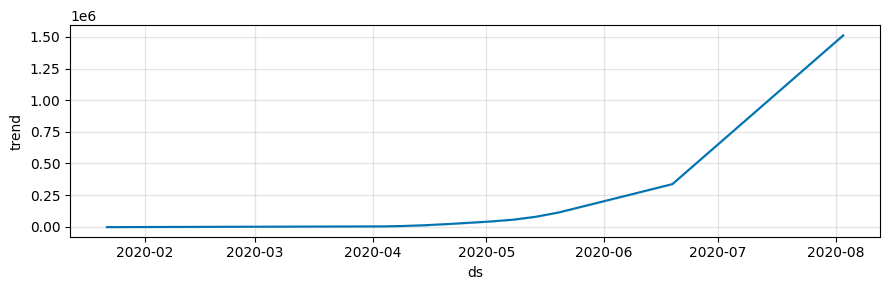

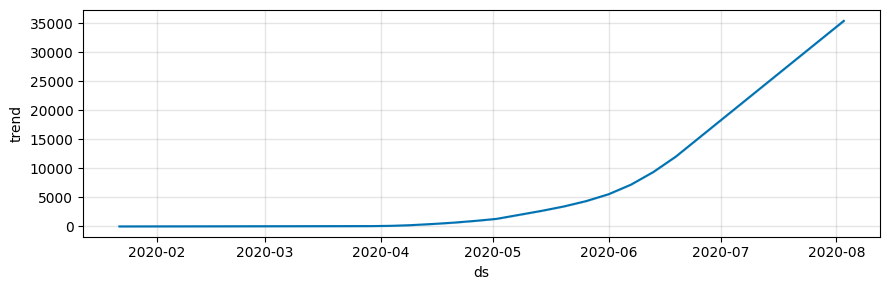

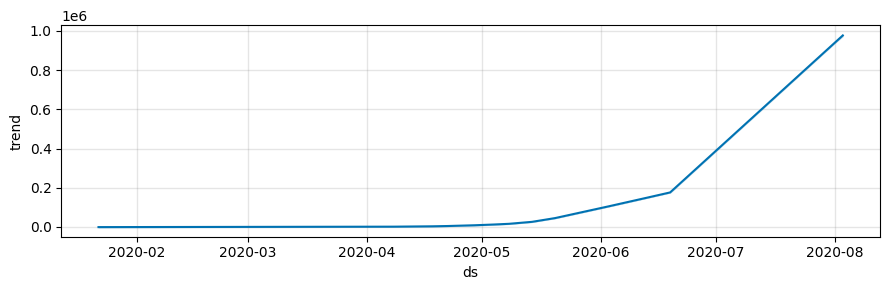

In [350]:
confirmed_model.plot_components(confirmed_IN_forecast)
plt.show()

deaths_model.plot_components(deaths_IN_forecast)
plt.show()

recovered_model.plot_components(recovered_IN_forecast)
plt.show()

In [351]:
print("Confirmed Cases Forecast")

display(confirmed_IN_7days)

print("Deaths Forecast")

display(deaths_IN_7days)

print("Recovered Cases Forecast")

display(recovered_IN_7days)

Confirmed Cases Forecast


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,1.355186e+06,1.320013e+06,1.392837e+06
189,2020-07-29,1.381287e+06,1.346379e+06,1.415041e+06
190,2020-07-30,1.407387e+06,1.369954e+06,1.443032e+06
191,2020-07-31,1.433487e+06,1.399008e+06,1.471337e+06
192,2020-08-01,1.459588e+06,1.422542e+06,1.495497e+06
193,2020-08-02,1.485688e+06,1.451600e+06,1.522957e+06
194,2020-08-03,1.511788e+06,1.474593e+06,1.548734e+06


Deaths Forecast


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,32317.557872,31885.937913,32784.355925
189,2020-07-29,32838.115273,32392.946274,33282.396798
190,2020-07-30,33358.672675,32902.800673,33785.253230
191,2020-07-31,33879.230076,33414.039007,34315.437242
192,2020-08-01,34399.787477,33947.303595,34855.080309
193,2020-08-02,34920.344879,34452.845432,35378.017986
194,2020-08-03,35440.902280,34954.452101,35879.472998


Recovered Cases Forecast


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,870153.457194,848875.327746,892171.922863
189,2020-07-29,887952.894280,866746.246742,910053.125728
190,2020-07-30,905752.331366,883133.216317,925952.674217
191,2020-07-31,923551.768451,901417.981708,945104.344239
192,2020-08-01,941351.205537,918691.854784,963875.283471
193,2020-08-02,959150.642623,936927.402284,980432.630294
194,2020-08-03,976950.079709,954818.714287,998856.168620


In [352]:
# Evaluate all three models
for column in ['Confirmed', 'Deaths', 'Recovered']:

    mae, rmse = evaluate_prophet(india_df, column)

    print(f'\n{column}')

    print('MAE:', mae)

    print('RMSE:', rmse)


Confirmed
MAE: 284737.33954141336
RMSE: 355901.0706015739

Deaths
MAE: 5741.710595198864
RMSE: 6479.387764512445

Recovered
MAE: 222068.33416529107
RMSE: 269501.5158727851
